In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Фиксируем seed, чтобы случайные данные были одинаковыми при каждом запуске
np.random.seed(42)

# 1. Генерация искусственных данных (по 1200 пользователей на группу)
n_users = 1200

group_a = pd.DataFrame({
    'user_id': range(1, n_users + 1),
    'group': 'A',
    # 50% вероятность конверсии
    'conversion': np.random.binomial(1, 0.50, n_users) 
})

group_b = pd.DataFrame({
    'user_id': range(n_users + 1, 2 * n_users + 1),
    'group': 'B',
    # 55% вероятность конверсии
    'conversion': np.random.binomial(1, 0.55, n_users)
})

# Объединяем в один датафрейм
df = pd.concat([group_a, group_b], ignore_index=True)

# 4. Генерация случайных меток времени в течение 2023 года
start_date = pd.to_datetime('2023-01-01')
end_date = pd.to_datetime('2023-12-31 23:59:59')
seconds_in_year = int((end_date - start_date).total_seconds())

random_seconds = np.random.randint(0, seconds_in_year, size=len(df))
df['timestamp'] = start_date + pd.to_timedelta(random_seconds, unit='s')

# 5. Извлекаем месяц и год
df['month'] = df['timestamp'].dt.month
df['year'] = df['timestamp'].dt.year

print(df.head())

   user_id group  conversion           timestamp  month  year
0        1     A           0 2023-08-20 23:32:58      8  2023
1        2     A           1 2023-06-02 05:06:54      6  2023
2        3     A           1 2023-03-11 13:32:14      3  2023
3        4     A           1 2023-05-13 02:50:02      5  2023
4        5     A           0 2023-06-17 23:10:53      6  2023


In [ ]:
# 2. Бутстрап-анализ
# Извлекаем случайные подвыборки с возвращением 

n_bootstraps = 100
boot_diffs = []

for i in range(n_bootstraps):
    boot_a_mean = df[df['group'] == 'A']['conversion'].sample(frac=1, replace=True).mean()
    boot_b_mean = df[df['group'] == 'B']['conversion'].sample(frac=1, replace=True).mean()
    boot_diffs.append(boot_b_mean - boot_a_mean)

# Считаем 95% доверительный интервал для разницы
ci_lower = np.percentile(boot_diffs, 2.5)
ci_upper = np.percentile(boot_diffs, 97.5)
print(f"95% Доверительный интервал разницы конверсий (B - A): от {ci_lower:.4f} до {ci_upper:.4f}")


# 3. Тест Хи-квадрат
# Создаем таблицу сопряженности (crosstab)
contingency_table = pd.crosstab(df['group'], df['conversion'])
print("\nТаблица сопряженности:")
print(contingency_table)

chi2, p_val, dof, expected = chi2_contingency(contingency_table)
print(f"\nP-value теста Хи-квадрат: {p_val:.4f}")

95% Доверительный интервал разницы конверсий (B - A): от -0.0017 до 0.0731

Таблица сопряженности:
conversion    0    1
group               
A           588  612
B           543  657

P-value теста Хи-квадрат: 0.0720


C:\Users\msi\AppData\Local\Temp\ipykernel_34372\2775285876.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


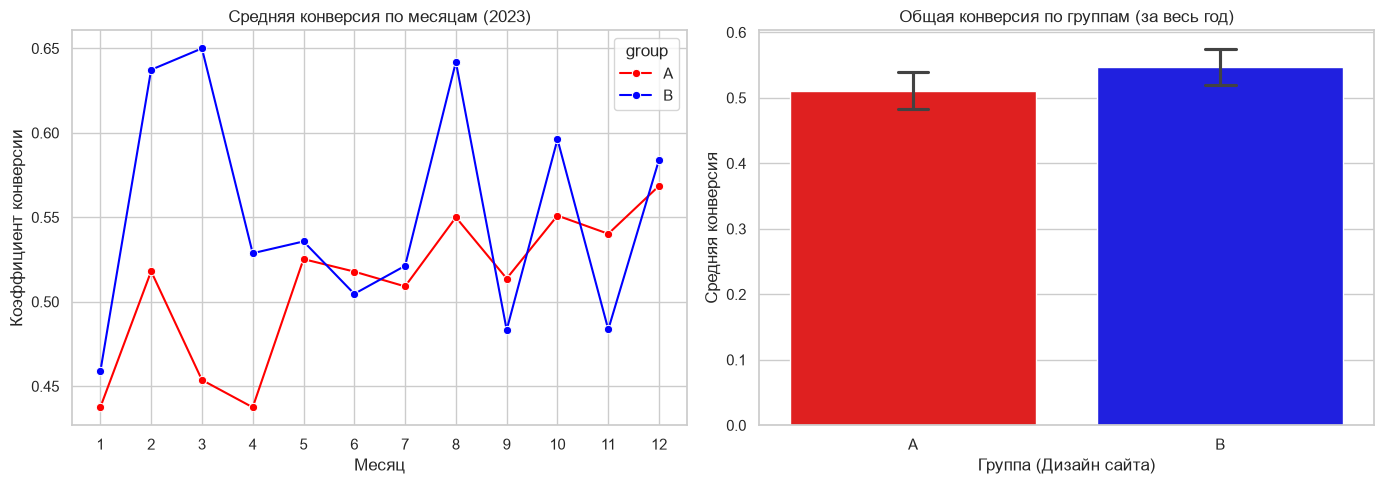

In [18]:
# Графики
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Изменение коэффициентов конверсии по месяцам
monthly_conv = df.groupby(['month', 'group'])['conversion'].mean().reset_index()
sns.lineplot(
    data=monthly_conv, x='month', y='conversion', 
    hue='group', marker='o', palette=['red', 'blue'], ax=axes[0]
)
axes[0].set_title('Средняя конверсия по месяцам (2023)')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Коэффициент конверсии')
axes[0].set_xticks(range(1, 13))

# График 2: Средняя конверсия за весь год с усами доверительного интервала
sns.barplot(
    data=df, x='group', y='conversion', 
    palette=['red', 'blue'], errorbar=('ci', 95), capsize=0.1, ax=axes[1]
)
axes[1].set_title('Общая конверсия по группам (за весь год)')
axes[1].set_xlabel('Группа (Дизайн сайта)')
axes[1].set_ylabel('Средняя конверсия')

plt.tight_layout()
plt.show()

### Выводы

1. **Различия в конверсии:** По условию задачи конверсия в группе (A) составила около 50%, а в тестовой группе (B) увеличилась примерно до 55%.
2. **Статистическая значимость:** 
   * **Тест Хи-квадрат** показал p-value = 0.072, что превышает стандартный порог значимости $\alpha = 0.05$. Это означает, что мы не можем отвергнуть нулевую гипотезу — наблюдаемые различия могли возникнуть случайно.
   * **Бутстрап-анализ** подтверждает этот вывод: 95% доверительный интервал разницы конверсий (B минус A) включает ноль (-0.0017 до 0.0731). 
3. **Динамика во времени:** График по месяцам показывает колебания конверсии, при которых группа B не демонстрирует стабильного преимущества в каждом периоде. (только в 4-х месяцах в году было явное преимущество группы В над конверсией группы А, тут возможен другой фактор, например активность пользователей в выборке.)

**ИТОГ**: Скорее всего, стоит либо увеличить "мощность" теста (увеличить объем групп А и В, т.к. ), либо увеличить продолжительность теста по времени. Либо вообще отклонить введение нового дизайна. 